4

k=1: класс = 1
k=3: класс = 1
k=5: класс = 0
k=15: класс = 0


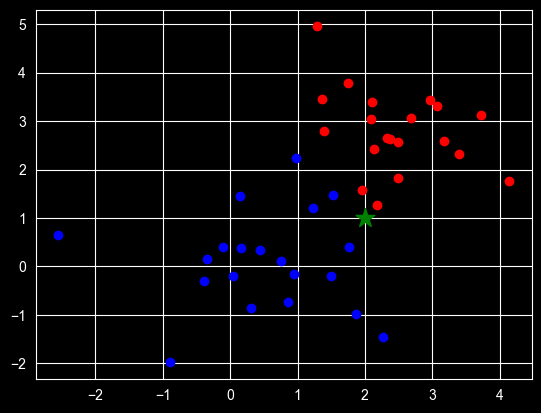

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


def knn_classify(X_train, y_train, x, k):
    # X_train — обучающие точки, форма (n, d)
    # y_train — метки классов, форма (n,)
    # x  — точка для классификации, форма (d,)
    # k  — число ближайших соседей

    distances = []

    for i in range(len(X_train)):
        d = euclidean(X_train[i], x)            # считаем расстояние от i-й точки до x
        distances.append((d, y_train[i]))

    distances.sort(key=lambda pair: pair[0])    # сортируем по расстоянию

    neighbors = distances[:k] 

    labels = []
    for pair in neighbors:
      distance = pair[0]
      label = pair[1]
      labels.append(label)

    counts = {}
    for label in labels:
        counts[label] = counts.get(label, 0) + 1

    best_class = max(counts, key=counts.get)

    return best_class

#пример
np.random.seed(0)

# Класс 1: 20 точек около (0, 0)
X1 = np.random.randn(20, 2) + np.array([0, 0])
y1 = np.zeros(20)

# Класс 2: 20 точек около (3, 3)
X2 = np.random.randn(20, 2) + np.array([3, 3])
y2 = np.ones(20)

X_train = np.vstack([X1, X2])
y_train = np.concatenate([y1, y2])

x = np.array([2.0, 1.0])

for k in [1, 3, 5, 15]:
    pred = knn_classify(X_train, y_train, x, k)
    print(f"k={k}: класс = {int(pred)}")

plt.scatter(X1[:,0], X1[:,1], c='blue')
plt.scatter(X2[:,0], X2[:,1], c='red')
plt.scatter(x[0], x[1], c='green', s=200, marker='*')
plt.grid(True)
plt.show()

5

In [2]:
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan(a, b):
    return np.sum(np.abs(a - b))

def chebyshev(a, b):
    return np.max(np.abs(a - b))

# lp — обобщение: при p=1 манхэттен, при p=2 евклид
def lp_distance(a, b, p):
    return np.sum(np.abs(a - b) ** p) ** (1 / p)

# канберра — устойчиво к разному масштабу признаков
def canberra(a, b):
    num = np.abs(a - b)
    den = np.abs(a) + np.abs(b)
    return np.sum(num / (den + 1e-10))

# ланса-уильямса — похоже на канберру, но через суммы
def lance_williams(a, b):
    num = np.sum(np.abs(a - b))
    den = np.sum(np.abs(a + b))
    return num / (den + 1e-10)

# косинус близости — угол между векторами, от -1 до 1
def cosine_similarity(a, b):
    num = np.dot(a, b)
    den = np.linalg.norm(a) * np.linalg.norm(b)
    return num / (den + 1e-10)

# косинус расстояние — то же, но как расстояние (0 = одинаковые)
def cosine_distance(a, b):
    return 1 - cosine_similarity(a, b)

# хэмминга — число несовпадающих позиций (для бинарных векторов)
def hamming(a, b):
    return np.sum(a != b)

In [3]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([4.0, 5.0, 6.0])

print("евклидово:", euclidean(a, b))
print("манхэттенское:", manhattan(a, b))
print("чебышёва:", chebyshev(a, b))
print("lp (p=3):", lp_distance(a, b, 3))
print("канберра", canberra(a, b))
print("ланса-уильямса:", lance_williams(a, b))
print("косинус близости:", cosine_similarity(a, b))
print("косинус расстояния:", cosine_distance(a, b))

c = np.array([1, 0, 1, 1, 0])
d = np.array([1, 1, 0, 1, 0])
print("хэмминга:       ", hamming(c, d))

евклидово: 5.196152422706632
манхэттенское: 9.0
чебышёва: 3.0
lp (p=3): 4.3267487109222245
канберра 1.3619047618829356
ланса-уильямса: 0.4285714285693878
косинус близости: 0.9746318461941077
косинус расстояния: 0.0253681538058923
хэмминга:        2


6


In [4]:
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def knn_regression(X_train, y_train, x, k):
    distances = []
    for i in range(len(X_train)):
        d = euclidean(X_train[i], x)
        distances.append((d, y_train[i]))

    distances.sort(key=lambda pair: pair[0])
    neighbors = distances[:k]

    values = [val for _, val in neighbors]
    return np.mean(values)

def knn_regression_weighted(X_train, y_train, x, k):
    distances = []
    for i in range(len(X_train)):
        d = euclidean(X_train[i], x)
        distances.append((d, y_train[i]))

    distances.sort(key=lambda pair: pair[0])
    neighbors = distances[:k]

    weights = np.array([1 / (d + 1e-10) for d, _ in neighbors])
    values = np.array([val for _, val in neighbors])

    return np.sum(weights * values) / np.sum(weights)

k=1: прогноз = -0.363
k=3: прогноз = -0.211
k=5: прогноз = -0.265
k=10: прогноз = -0.336
истинное значение sin(3.5) = -0.35078322768961984


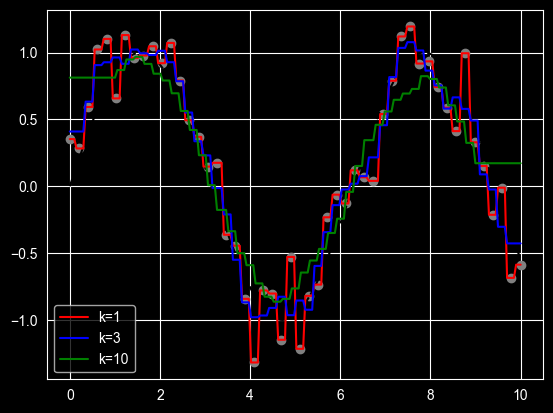

In [5]:
np.random.seed(0)
X_train = np.linspace(0, 10, 50).reshape(-1, 1)
y_train = np.sin(X_train).ravel() + np.random.randn(50) * 0.2

x = np.array([3.5])

for k in [1, 3, 5, 10]:
    pred = knn_regression(X_train, y_train, x, k)
    print(f"k={k}: прогноз = {pred:.3f}")

print("истинное значение sin(3.5) =", np.sin(3.5))

x_grid = np.linspace(0, 10, 200)
plt.scatter(X_train, y_train, c='gray')
plt.plot(x_grid, np.sin(x_grid), 'k--')
for k, color in zip([1, 3, 10], ['red', 'blue', 'green']):
    y_pred = [knn_regression(X_train, y_train, np.array([xi]), k) for xi in x_grid]
    plt.plot(x_grid, y_pred, color=color, label=f'k={k}')
plt.legend(); plt.grid(True)
plt.show()

7

In [6]:
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

# находим центроид одного класса — среднее по всем точкам
def compute_centroid(points):
    return np.mean(points, axis=0)

# находим центроиды всех классов
def compute_all_centroids(X_classes):
    centroids = []
    for points in X_classes:
        centroids.append(compute_centroid(points))
    return np.array(centroids)

# классификация точки x по ближайшему центроиду
def classify_by_centroids(centroids, x):
    distances = []
    for c in centroids:
        distances.append(euclidean(c, x))
    return np.argmin(distances)

  класс 0: [0.7182032 0.1675097]
  класс 1: [4.44191907 4.97903722]
  класс 2: [ 9.87597318 -0.14341517]
точка [1. 2.] отнесена к классу 0


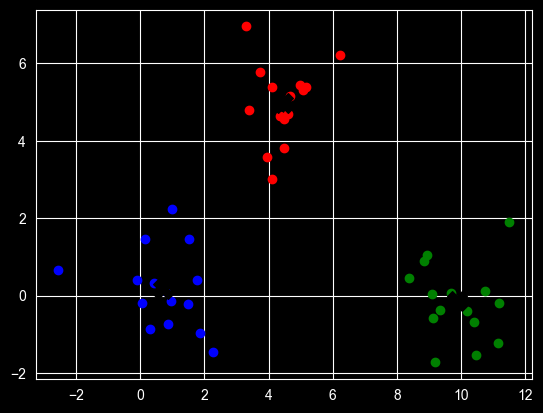

In [7]:
np.random.seed(0)

# три класса по 15 точек
X1 = np.random.randn(15, 2) + np.array([0, 0])      # класс 0 около (0, 0)
X2 = np.random.randn(15, 2) + np.array([5, 5])      # класс 1 около (5, 5)
X3 = np.random.randn(15, 2) + np.array([10, 0])     # класс 2 около (10, 0)

X_classes = [X1, X2, X3]

centroids = compute_all_centroids(X_classes)        # считаем центроиды

for i, c in enumerate(centroids): # перебирает центроиды и одновременно выдаёт их номера.
    print(f"  класс {i}: {c}")

x = np.array([1.0, 2.0])                            # новая точка
pred = classify_by_centroids(centroids, x)          # классифицируем
print(f"точка {x} отнесена к классу {pred}")

plt.scatter(X1[:,0], X1[:,1], c='blue')
plt.scatter(X2[:,0], X2[:,1], c='red')
plt.scatter(X3[:,0], X3[:,1], c='green')
for cen in centroids:
    plt.scatter(cen[0], cen[1], c='black', s=200, marker='X')
plt.grid(True)
plt.show()